In [1]:
# Импорт библиотек
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


pd.set_option('display.max_columns', None)

In [3]:
# 1. Загрузка данных
GUILD_PATH = "guild_data.csv"
ENERGY_PATH = "energy.csv"


guild = pd.read_csv(GUILD_PATH)
energy = pd.read_csv(ENERGY_PATH)


print("Размеры датафреймов:")
print("guild_data:", guild.shape)
print("energy:", energy.shape)

guild.head()

Размеры датафреймов:
guild_data: (965, 12)
energy: (971, 3)


,datetime,creator_character_id,guild_id,n_added_characters,n_removed_characters,n_talents,level,n_missions_completed,n_times_flag_turned_on,mean_place,mean_rating,n_seasons
0,2022-12-12 23:13:42,15092203,78698,1,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-12-12 22:29:09,15961764,78604,2,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-12-12 21:01:53,16187808,78510,27,19.0,9.0,2.0,171.0,NaN,NaN,NaN,NaN
3,2022-12-12 00:16:52,21618959,77899,42,35.0,12.0,3.0,171.0,NaN,NaN,NaN,NaN
4,2022-12-12 22:13:50,23341705,78557,6,6.0,4.0,2.0,156.0,NaN,NaN,NaN,NaN


In [4]:
guild.describe().T

,count,mean,std,min,25%,50%,75%,max
creator_character_id,965.0,2.323599e+07,3.926890e+06,10631353.0,21140973.00,23958657.0,26318342.0,29090532.0
guild_id,965.0,7.296400e+04,1.309964e+04,50310.0,61637.00,72964.0,84291.0,95618.0
n_added_characters,965.0,3.288808e+01,3.689378e+01,1.0,4.00,20.0,49.0,283.0
n_removed_characters,866.0,3.104734e+01,3.465188e+01,1.0,5.00,19.0,47.0,265.0
n_talents,672.0,1.542262e+01,1.525433e+01,1.0,6.00,11.0,20.0,109.0
level,572.0,3.097902e+00,1.176624e+00,2.0,2.00,3.0,4.0,8.0
n_missions_completed,895.0,1.376458e+02,6.512182e+01,1.0,86.00,169.0,171.0,279.0
n_times_flag_turned_on,81.0,1.839506e+00,1.427032e+00,1.0,1.00,1.0,2.0,8.0
mean_place,59.0,1.502429e+01,7.262593e+00,2.5,10.00,14.0,18.5,35.0
mean_rating,59.0,4.750788e+02,5.252882e+01,320.0,445.25,477.0,500.0,604.0


In [5]:
energy.head()

,energy_delta,context_type,guild_id
0,1148686,GuildMissionRewardContext,90166
1,1018116,GuildMissionRewardContext,81283
2,907440,GuildMissionRewardContext,79262
3,889109,GuildMissionRewardContext,84667
4,858954,GuildMissionRewardContext,77241


In [8]:
# 2. Очистка данных по гильдиям и объединение с таблицей energy
guild_full = guild.merge(
    energy.groupby("guild_id", as_index = False)["energy_delta"].sum().rename(columns={"energy_delta":"total_energy"}),
    on="guild_id",
    how="left"
).fillna(0)

In [9]:
guild_full.head()

,datetime,creator_character_id,guild_id,n_added_characters,n_removed_characters,n_talents,level,n_missions_completed,n_times_flag_turned_on,mean_place,mean_rating,n_seasons,total_energy
0,2022-12-12 23:13:42,15092203,78698,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2022-12-12 22:29:09,15961764,78604,2,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2022-12-12 21:01:53,16187808,78510,27,19.0,9.0,2.0,171.0,0.0,0.0,0.0,0.0,24680.0
3,2022-12-12 00:16:52,21618959,77899,42,35.0,12.0,3.0,171.0,0.0,0.0,0.0,0.0,37480.0
4,2022-12-12 22:13:50,23341705,78557,6,6.0,4.0,2.0,156.0,0.0,0.0,0.0,0.0,11140.0


In [10]:
# 3. Формирование признаков активности
activity_features = [
    "n_added_characters",
    "n_removed_characters",
    "n_talents",
    "level",
    "n_missions_completed",
    "n_times_flag_turned_on",
    "n_seasons",
    "mean_rating",
    "total_energy",
]

# Если есть mean_place, добавим battle_score 
if "mean_place" in guild_full.columns:
    guild_full["battle_score"] = -guild_full["mean_place"]
    activity_features.append("battle_score")

X= guild_full[activity_features].copy()

print("Матрица активных признаков:")
X.head()

Матрица активных признаков:


,n_added_characters,n_removed_characters,n_talents,level,n_missions_completed,n_times_flag_turned_on,n_seasons,mean_rating,total_energy,battle_score
0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0
1,2,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0
2,27,19.0,9.0,2.0,171.0,0.0,0.0,0.0,24680.0,-0.0
3,42,35.0,12.0,3.0,171.0,0.0,0.0,0.0,37480.0,-0.0
4,6,6.0,4.0,2.0,156.0,0.0,0.0,0.0,11140.0,-0.0


In [12]:
# 4. Масштабирование признаков и общий activity_score
scaler = StandardScaler()
X_scaled=scaler.fit_transform(X)

guild_full["activity_score"] = X_scaled.sum(axis = 1)
guild_full[["guild_id", "activity_score"]].head()

,guild_id,activity_score
0,78698,-6.040025
1,78604,-5.983609
2,78510,-0.565108
3,77899,1.145717
4,78557,-2.135059


In [13]:
import os
import warnings

# ограничиваем число потоков
os.environ["OMP_NUM_THREADS"] = "4"

# предупреждение
warnings.filterwarnings(
    "ignore",
    category=UserWarning,
    message="KMeans is known to have a memory leak*"
)


k = 2: inertia = 6099, silhouette = 0.6871
k = 3: inertia = 3959, silhouette = 0.4663
k = 4: inertia = 2989, silhouette = 0.4844
k = 5: inertia = 2366, silhouette = 0.4788
k = 6: inertia = 1886, silhouette = 0.4837


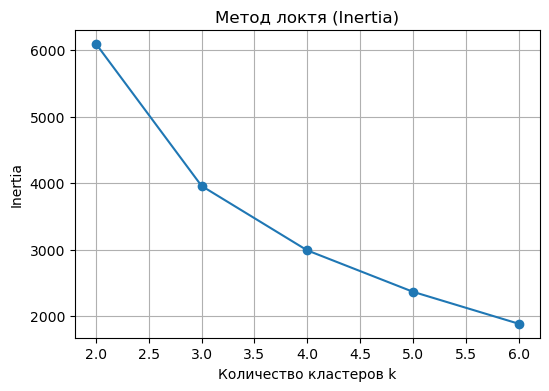

Оптимальное количество кластеров по silhouette: k = 2


In [14]:
# 5. Подбор количества кластеров KMeans
#Метод локтя + silhouette_score
inertias = []
silhouette_scores = {}
K_MIN, K_MAX = 2, 6

for k in range(K_MIN, K_MAX + 1):
    kmeans_tmp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_tmp = kmeans_tmp.fit_predict(X_scaled)
    inertia = kmeans_tmp.inertia_
    inertias.append(inertia)
    
    sil = silhouette_score(X_scaled, labels_tmp)
    silhouette_scores[k] = sil
    print(f"k = {k}: inertia = {inertia:.0f}, silhouette = {sil:.4f}")

plt.figure(figsize=(6,4))
plt.plot(range(K_MIN, K_MAX + 1), inertias, marker="o")
plt.title("Метод локтя (Inertia)")
plt.xlabel("Количество кластеров k")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"Оптимальное количество кластеров по silhouette: k = {best_k}")

In [15]:
# 6. Финальная кластеризация с выбранным k
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
guild_full["cluster"] = kmeans.fit_predict(X_scaled)

print("Распределение гильдий по кластерам:")
guild_full["cluster"].value_counts().sort_index()

Распределение гильдий по кластерам:


cluster
0     80
1    885
Name: count, dtype: int64

In [16]:
# 7. Интерпретация кластеров и уровни активности

# 1. Считаем средний activity_score по каждому кластеру и сортируем по возрастанию
cluster_scores = (
    guild_full.groupby("cluster")["activity_score"]
              .mean()
              .sort_values()
)

print("Средний activity_score по кластерам (чем выше, тем активнее):")
print(cluster_scores)

# 2. Получаем кластеры в порядке от менее активного к более активному
sorted_clusters = cluster_scores.index.tolist()

# 3. Задаём два уровня активности
labels_for_k = ["Inactive", "Active"]  

# 4. Строим мэппинг: кластер с меньшим score - "Inactive", с большим - "Active"
cluster_to_label = {
    cl: label for cl, label in zip(sorted_clusters, labels_for_k)
}

# 5. Применяем мэппинг к гильдиям
guild_full["activity_level"] = guild_full["cluster"].map(cluster_to_label)

print("Мэппинг кластеров - уровни активности:")
print(cluster_to_label)

print("Пример гильдий с уровнем активности:")
guild_full[["guild_id", "creator_character_id", "activity_score", "cluster", "activity_level"]].head()

Средний activity_score по кластерам (чем выше, тем активнее):
cluster
1    -1.310598
0    14.498495
Name: activity_score, dtype: float64
Мэппинг кластеров - уровни активности:
{1: 'Inactive', 0: 'Active'}
Пример гильдий с уровнем активности:


,guild_id,creator_character_id,activity_score,cluster,activity_level
0,78698,15092203,-6.040025,1,Inactive
1,78604,15961764,-5.983609,1,Inactive
2,78510,16187808,-0.565108,1,Inactive
3,77899,21618959,1.145717,1,Inactive
4,78557,23341705,-2.135059,1,Inactive


In [17]:
guild_full[guild_full["cluster"] == 1][[
    "guild_id", 
    "creator_character_id", 
    "activity_score", 
    "cluster", 
    "activity_level"
]].head()

,guild_id,creator_character_id,activity_score,cluster,activity_level
0,78698,15092203,-6.040025,1,Inactive
1,78604,15961764,-5.983609,1,Inactive
2,78510,16187808,-0.565108,1,Inactive
3,77899,21618959,1.145717,1,Inactive
4,78557,23341705,-2.135059,1,Inactive


In [18]:
# 8. Доля неактивных гильдий (гипотеза 1)
inactive_cluster = sorted_clusters[0]
n_inactive = (guild_full["cluster"] == inactive_cluster).sum()
n_total = guild_full.shape[0]
inactive_share = n_inactive / n_total

print(f"Всего гильдий: {n_total}")
print(f"Неактивных (кластер {inactive_cluster}, {cluster_to_label[inactive_cluster]}): {n_inactive}")
print(f"Доля неактивных гильдий: {inactive_share:.2%}")

Всего гильдий: 965
Неактивных (кластер 1, Inactive): 885
Доля неактивных гильдий: 91.71%
